In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=2)

Going to make a model that takes 2 inputs and returns 1

In [ ]:
def plot_3d(x,z,y):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(x,z,y,color="orange")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")
    plt.show()

In [ ]:
#Training data:
scale = 100
deviation = 0.1
w = np.array([20,30])
b = 30
x_input = np.random.uniform(-scale,scale,size=(scale,2))
y_output = x_input @ w + b + np.random.normal(0,scale*deviation,size=(scale))
print(x_input)
plot_3d(x_input[:,0],x_input[:,1],y_output)


In [ ]:
#Cost function:
def cost_function(x, y, w, b):
    y_hat = (x @ w + b)
    return np.sum((y_hat-y)**2)/2,y_hat

In [ ]:
#Testing cost function
w = np.array([20,30])
b = 30
print(f"cost: {cost_function(x_input, y_output, w, b)[0]:.2f}")

In [ ]:

w = np.random.uniform(-1,1,size=(2))
b = np.random.uniform(-1,1,size=(1))[0]
cost,y_hat = cost_function(x_input,y_output,w,b)

print(f"Cost value: {cost:.2f} Values: {w},{b:.2f}")

cost_history = []
learning_rate = 0.000001

cut_off = 0.01

max_iterations = 10000

for _ in range(max_iterations):
    error = y_hat-y_output
    new_w = w - learning_rate*np.average(error*x_input.T,axis=1)
    new_b = b - learning_rate*np.average(error)
    w,b = new_w,new_b

    new_cost,y_hat = cost_function(x_input, y_output, w, b)

    if (abs(new_cost-cost) < cut_off):
        break
    cost = new_cost
    cost_history.append(cost)
print(f"Cost value: {cost:.2f} Values: {w},{b:.2f}")


In [114]:
#Gradient descent function:
def linear_regression(x,y,learning_rate = 0.001,cut_off = 0.01,max_iterations = 10000):
    w = np.random.uniform(-1,1,size=(x.shape[1]))
    b = np.random.uniform(-1,1,size=(1))[0]
    cost,y_hat = cost_function(x,y,w,b)
    for _ in range(max_iterations):
        error = y-y_hat
        new_w = w - learning_rate*np.average(error*x.T,axis=1)
        new_b = b - learning_rate*np.average(error)
        w,b = new_w,new_b

        new_cost,y_hat = cost_function(x, y, w, b)

        if (abs(new_cost-cost) < cut_off):
            return w,b
        cost = new_cost
    return w,b

Values: [-5.69e+14 -3.53e+14],-282027486884.13


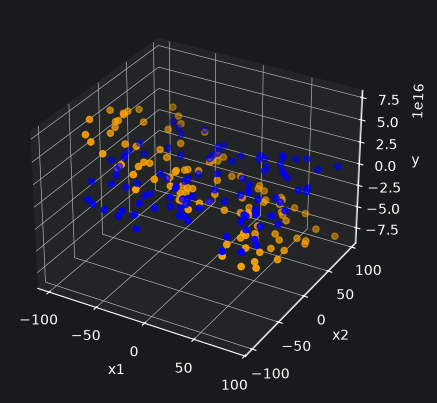

In [128]:
#Testing linear_regression
w,b = linear_regression(x_input,y_output,0.000001,0.001)
print(f"Values: {w},{b:.2f}")
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*x_input.T,y_output,color="blue")
ax.scatter(*x_input.T,x_input @ w + b,color="orange")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
plt.show()

In [ ]:
#brute force:

cost = np.inf
w,b = 0,0
cost_history = []
for i in range(100):
    new_w = np.random.uniform(-5,5,size=(2))
    new_b = np.random.uniform(-5,5,size=(1))[0]
    new_cost = cost_function(x_input, y_output,new_w,new_b)[0]
    if new_cost < cost:
        cost_history.append(new_cost)
        cost = new_cost
        w,b = new_w,new_b
        print(f"Cost value: {new_cost:.2f} Values: {w},{b:.2f}")

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*x_input.T,y_output,color="blue")
ax.scatter(*x_input.T,x_input @ w + b,color="orange")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
plt.show()
